# Week 4 — Embeddings and similarity

Goal: embed 30–50 paragraphs of public model-risk guidance, compare them with cosine similarity, cluster them with k-means, plot the clusters in 2D and say what each cluster is about.

**Set up in advance:** loading the two documents and splitting them into paragraphs (steps 0–1).
**Done in the notebook:** embeddings, the similarity matrix, clustering, the plot and the cluster labels (steps 2–6).

Run this notebook with the `.venv` kernel.

## Step 0 — Setup

Two sources, both public:

- **SR 26-2** (Federal Reserve, April 2026): the current interagency model risk management guidance. All of its paragraphs are used.
- **OCC *Model Risk Management* booklet** (Comptroller's Handbook, version 1.0, August 2021): the OCC's examiner booklet. The OCC rescinded it when SR 26-2 replaced the older guidance, and the OCC no longer hosts it, so this copy comes from a third-party site. It is a different kind of document: it describes what *examiners* look for. It has about 150 usable paragraphs, so only 12 evenly spaced ones are taken, to keep the total near 50.

In [1]:
import re
from pathlib import Path

import numpy as np

DOCS = Path("docs")

# (file, how its layout is split, how many paragraphs to keep; None = all)
SOURCES = [
    ("SR2602a1.txt", "indented", None),                  # SR2602.txt repeats this text, so only one of them is loaded
    ("OCC-model-risk-booklet-2021.txt", "blank_lines", 12),
]

## Step 1 — Split the documents into paragraphs

`pdftotext -layout` keeps the page layout, so lines break mid-sentence. The two documents are laid out differently, so each gets its own splitter:

- **SR 26-2:** a paragraph starts with an indented line and its continuation lines are not indented. Blank lines can't be used, because the file is double-spaced.
- **OCC booklet:** paragraphs are separated by blank lines. The splitter starts at the *Introduction* heading and stops at *Examination Procedures*, because the rest is a checklist of questions, not prose.

Both drop page numbers, running headers and short section headings, join each paragraph into one line, and keep only paragraphs of a minimum length.

If you add another document, check its layout and the splitter's output before trusting it.

In [2]:
def paragraphs_indented(path, min_words=25):
    """Paragraphs of a pdftotext -layout file where each paragraph starts with an indented line."""
    out, cur = [], []

    def flush():
        if cur:
            out.append(re.sub(r"\s+", " ", " ".join(cur)).strip())
            cur.clear()

    for page in Path(path).read_text().split("\f"):          # \f marks a page break
        for line in page.splitlines():
            s = line.strip()
            if not s or re.fullmatch(r"\d{1,3}", s):          # blank lines and bare page numbers
                continue
            if re.match(r"^([IVX]+|[A-Z])\.\s+[A-Z]", s) and s.upper() == s:   # headings like "II. PURPOSE AND SCOPE"
                flush()
                continue
            if line.startswith("    ") and cur:               # an indented line starts a new paragraph
                flush()
            cur.append(s)
    flush()                                                   # no flush at page ends: paragraphs can span pages
    return [p for p in out if len(p.split()) >= min_words]


def paragraphs_blank_lines(path, min_words=40, start="Introduction", stop="Examination Procedures"):
    """Paragraphs separated by blank lines, taken from the page with the `start` heading up to the `stop` heading."""
    pages = Path(path).read_text().split("\f")
    first = next(i for i, p in enumerate(pages) if i >= 1 and re.search(rf"^{start}\s*$", p, re.M))   # skips the table of contents
    last = next(i for i, p in enumerate(pages) if i > first and re.search(rf"^{stop}\s*$", p, re.M))
    out = []
    for page in pages[first:last]:
        for block in re.split(r"\n\s*\n", page):
            lines = [l.strip() for l in block.splitlines() if l.strip()]
            lines = [l for l in lines if not re.fullmatch(r"(Version 1\.0|Comptroller.s Handbook\s*\d*|\d{1,3}|\d{1,3}\s+Comptroller.s Handbook)", l)]
            while len(lines) > 1 and len(lines[0].split()) <= 6 and not lines[0].endswith((".", "?", ":", ";", ")")):
                lines.pop(0)                                   # a section heading glued to the paragraph below it
            if not lines or lines[0][0] in "•-–":              # bullet lists are skipped
                continue
            p = re.sub(r"\s+", " ", " ".join(lines))
            if len(p.split()) >= min_words and p[-1] in ".?:)" and not re.search(r"\.{5,}", p):
                out.append(p)
    return out


def evenly_spaced(items, n):
    """n items spread evenly across the list, so every section is represented."""
    if n is None or n >= len(items):
        return items
    return [items[int(i * len(items) / n)] for i in range(n)]


SPLITTERS = {"indented": paragraphs_indented, "blank_lines": paragraphs_blank_lines}

In [3]:
texts, sources = [], []
for name, layout, keep in SOURCES:
    ps = SPLITTERS[layout](DOCS / name)
    chosen = evenly_spaced(ps, keep)
    print(f"{name}: {len(ps)} paragraphs found, {len(chosen)} used")
    texts += chosen
    sources += [name] * len(chosen)

words = [len(t.split()) for t in texts]
print(f"\n{len(texts)} paragraphs in total; words per paragraph min/median/max: {min(words)}/{int(np.median(words))}/{max(words)}")
for i in (0, len(texts) // 2, len(texts) - 1):
    print(f"\n[{i}] ({sources[i]}) {texts[i][:200]}...")

SR2602a1.txt: 38 paragraphs found, 38 used
OCC-model-risk-booklet-2021.txt: 152 paragraphs found, 12 used

50 paragraphs in total; words per paragraph min/median/max: 40/69/184

[0] (SR2602a1.txt) Use of models within the banking and financial services industries continues to grow in complexity and scope. Advances in technology along with increased competition have driven banking organizations ...

[25] (SR2602a1.txt) The quality of validation process depends on the rigor and effectiveness of the review rather than on organizational structure of the banking organization’s risk management function. Technical knowled...

[49] (OCC-model-risk-booklet-2021.txt) Back-testing is one form of outcomes analysis; specifically, it involves the comparison of actual outcomes with model forecasts during a sample time period not used in model development, and at an obs...


In [5]:
texts

['Use of models within the banking and financial services industries continues to grow in complexity and scope. Advances in technology along with increased competition have driven banking organizations to leverage innovative approaches to improve efficiencies, better mitigate risks, and help maximize profits. Continued use of models is essential to maintaining the competitiveness of banking organizations in the financial system.',
 'Use of models also can present substantial risk. Such risk, generally referred to as “model risk” for purposes of this guidance, can lead to financial loss, errors in financial statements and reporting, and flawed financial and risk management decisions, among other types of risk events. Model risk can be mitigated through active and appropriate risk management, recognizing that the relevance of model risk depends on the nature, scale, and use of the models in relation to the associated business risks.',
 'This guidance highlights sound principles for effec

## Step 2 — Embed the paragraphs

An embedding turns a paragraph into a vector, so that paragraphs with similar meaning end up close together.

In [15]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")   # small model, 384-dimensional vectors, runs on CPU
embedding = model.encode(texts)                    # one row per paragraph, in the same order as `texts`

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [16]:
embedding.shape   # (number of paragraphs, 384)

(50, 384)

## Step 3 — Cosine similarity

Cosine similarity compares the *direction* of two vectors: 1 means the same direction, 0 means unrelated, negative means opposite. The formula is `a·b / (|a| |b|)`.

In [17]:
from sklearn.metrics.pairwise import cosine_similarity

# 50 x 50 matrix: entry [i, j] is the cosine similarity between paragraph i and paragraph j
cos_sim_text_encoded = cosine_similarity(X=embedding)

In [12]:
cos_sim_text_encoded   # diagonal is 1: every paragraph is identical to itself

array([[1.        , 0.5450779 , 0.66112083, ..., 0.46061367, 0.2971226 ,
        0.34817004],
       [0.5450779 , 0.9999999 , 0.72301066, ..., 0.43971732, 0.29707628,
        0.35784006],
       [0.66112083, 0.72301066, 1.0000001 , ..., 0.51755464, 0.37594458,
        0.34844568],
       ...,
       [0.46061367, 0.43971732, 0.51755464, ..., 1.        , 0.554911  ,
        0.57801056],
       [0.2971226 , 0.29707628, 0.37594458, ..., 0.554911  , 0.9999999 ,
        0.50146127],
       [0.34817004, 0.35784006, 0.34844568, ..., 0.57801056, 0.50146127,
        1.        ]], shape=(50, 50), dtype=float32)

## Step 4 — Cluster with k-means

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

labels = {}                      # labels[k] = cluster id for each paragraph, for that k
for k in range(3, 9):            # try 3 to 8 clusters
    # n_init=10: run k-means 10 times from different starts and keep the best; random_state makes it repeatable
    labels[k] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(embedding)
    # silhouette: -1 to 1, higher means tighter and better separated clusters
    print(k, round(silhouette_score(embedding, labels[k]), 3))

3 0.086
4 0.098
5 0.074
6 0.059
7 0.089
8 0.083


All six scores are low (0.06–0.10), and that is normal for paragraphs from related documents. The highest is k=4 at 0.098, but k=3 (0.086) and k=7 (0.089) are close, within about 0.01. The score can't separate those three, so it doesn't give you a clear winner. The pattern is also not smooth. Scores fall to 0.059 at k=6 and then rise again at k=7, which suggests there is no strong natural number of clusters in this data.

In [42]:
best_k = 4                       # chosen from the silhouette scores and by reading the clusters
best_labels = labels[best_k]     # cluster id of each paragraph for that k

In [43]:
# Show the first 5 paragraphs of each cluster, to judge what the cluster is about
for c in range(4):
    print(f"\n--- cluster {c} ({(labels[4] == c).sum()} paragraphs) ---")
    for i in np.where(labels[4] == c)[0][:5]:      # positions of the paragraphs in cluster c
        print(f"[{sources[i]}] {texts[i][:250]}...")


--- cluster 0 (7 paragraphs) ---
[SR2602a1.txt] Validation provides insight into the reliability of a given model, based on its underlying assumptions, methods, data, and relevant theories, as appropriate. This understanding helps characterize the source and extent of the model risk. Validation ca...
[SR2602a1.txt] Outcomes analysis compares model outputs to corresponding real-world outcomes to assess model performance relative to model objectives and business use. Outcomes analysis and other elements of the validation process may identify material errors or pe...
[SR2602a1.txt] Outcomes analysis can take many forms, including testing conducted during model development, reports or analysis performed as part of ongoing monitoring, or standalone activities such as back-testing or outlier analysis. A banking organization’s appr...
[SR2602a1.txt] Ongoing model monitoring involves an evaluation of the extent to which a model is performing as expected given potential changes in products, ex

Clusters 0–3 turn out to be, "validation", "governance", "inventory/documentation" and "OCC examiner procedures", that supports k=4.

Clusters 0–3 turn out to be, "validation", "governance", "inventory/documentation" and "OCC examiner procedures", that supports k=4.

In [44]:
import collections

# Count the paragraphs from each source in each cluster: do clusters follow topics or documents?
for c in range(4):
    print(c, collections.Counter(sources[i] for i in np.where(labels[4] == c)[0]))

0 Counter({'SR2602a1.txt': 5, 'OCC-model-risk-booklet-2021.txt': 2})
1 Counter({'SR2602a1.txt': 6, 'OCC-model-risk-booklet-2021.txt': 3})
2 Counter({'SR2602a1.txt': 18, 'OCC-model-risk-booklet-2021.txt': 6})
3 Counter({'SR2602a1.txt': 9, 'OCC-model-risk-booklet-2021.txt': 1})


## Step 5 — Plot the clusters in 2D

variance kept by PC1, PC2: [0.147 0.098] total 0.246


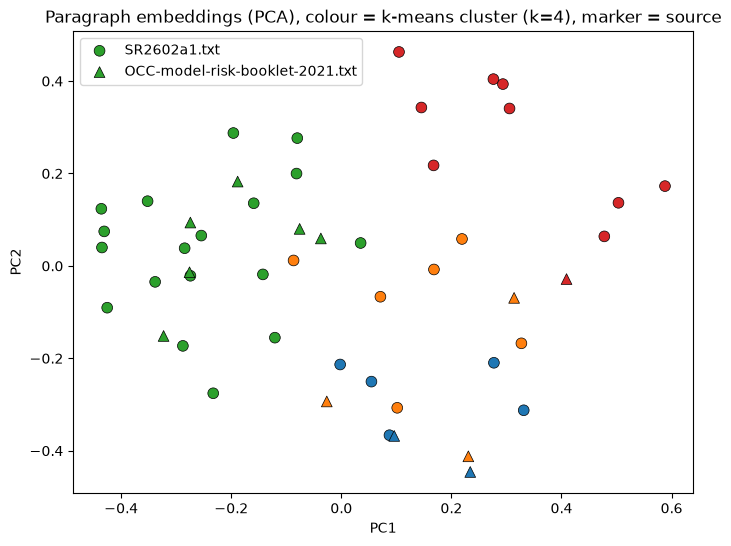

In [45]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Squeeze the 384 dimensions down to 2 so the paragraphs can be drawn on a plane
pca = PCA(n_components=2)
xy = pca.fit_transform(embedding)
# Share of the original information kept by each of the 2 axes
print("variance kept by PC1, PC2:", pca.explained_variance_ratio_.round(3), "total", pca.explained_variance_ratio_.sum().round(3))

best_labels = labels[4]
markers = {"SR2602a1.txt": "o", "OCC-model-risk-booklet-2021.txt": "^"}   # marker shape = source document

fig, ax = plt.subplots(figsize=(8, 6))
for name, m in markers.items():                      # one scatter call per source, so each gets its own marker
    idx = [i for i, s in enumerate(sources) if s == name]
    ax.scatter(xy[idx, 0], xy[idx, 1], c=best_labels[idx], cmap="tab10", vmin=0, vmax=9,   # colour = cluster
               marker=m, s=60, edgecolor="k", linewidth=0.5, label=name)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Paragraph embeddings (PCA), colour = k-means cluster (k=4), marker = source")
ax.legend()
plt.savefig("figures/clusters.png", dpi=150, bbox_inches="tight")
plt.show()

Markers for the source is spread arounf in the picture. That shows the results won't probably carry much of bias with respect to the source. The explained variance is small and the put uncertainty to the overall of the output.

## Step 6 — Label each cluster 

Read 3–4 paragraphs from each cluster and write a short label for what the cluster is about. Write your labels in the table below.

| Cluster | Sample paragraphs | Label | Evidence (example phrases) |
|---|---|---|---|
| 0 (7 paragraphs) | (SR 26-2, #23) Validation provides insight into the reliability of a given model, based on its underlying assumptions, methods, data, and relevant theories, as appropriate. This understanding helps characterize the source and extent of the...<br><br>(SR 26-2, #28) Outcomes analysis compares model outputs to corresponding real-world outcomes to assess model performance relative to model objectives and business use. Outcomes analysis and other elements of the validation process may identify...<br><br>(SR 26-2, #30) Ongoing model monitoring involves an evaluation of the extent to which a model is performing as expected given potential changes in products, exposures, activities, clients, data relevance, or market conditions. A model that no...<br><br>(OCC, #47) Outcomes analysis and the other elements of the validation process may reveal significant errors or inaccuracies in model development or outcomes that consistently fall outside the bank’s predetermined thresholds of... | Model performance |  "reliability of a given model","to assess model performance", "inaccuracies in model development or outcomes"|
| 1 (9 paragraphs) | (SR 26-2, #7) For the purposes of this guidance, the term “model” refers to a complex quantitative method, system, or approach that applies statistical, economic, or financial theories to process input data into quantitative estimates. The...<br><br>(SR 26-2, #18) An effective development process generally begins with a clear statement of purpose to maximize the likelihood that model development is aligned with the intended use. This fundamental step supports decision-making throughout the...<br><br>(SR 26-2, #20) Model testing is a core component of model development that evaluates whether a model performs as intended. Testing may include a range of activities, from out-of-sample and out-of- time testing, to a comparison of alternative...<br><br>(OCC, #44) The data and other information used to develop a model are of critical importance; there should be rigorous assessment of data quality and relevance, and appropriate documentation. Developers should be able to demonstrate that... | Model definition and development | "purposes of this guidance", "a core component of model development", "there should be rigorous assessment of data quality and relevance"|
| 2 (24 paragraphs) | (SR 26-2, #0) Use of models within the banking and financial services industries continues to grow in complexity and scope. Advances in technology along with increased competition have driven banking organizations to leverage innovative...<br><br>(SR 26-2, #6) This guidance is expected to be most relevant to banking organizations with over $30 See 12 CFR Part 4, Subpart F, Appendix A (OCC); 12 CFR Part 262, Appendix A (Board); 12 CFR Part 302, Appendix A (FDIC). However, supervisory...<br><br>(SR 26-2, #25) The quality of validation process depends on the rigor and effectiveness of the review rather than on organizational structure of the banking organization’s risk management function. Technical knowledge and modeling expertise...<br><br>(OCC, #38) The Office of the Comptroller of the Currency’s (OCC) Comptroller’s Handbook booklet, “Model Risk Management,” is prepared for use by OCC examiners in connection with their examination and supervision of national banks, federal... | Overview and scope of model risk management | "continues to grow in complexity and scope", "This guidance is expected to be most relevant to...", "is prepared for use by OCC examiners" |
| 3 (10 paragraphs) | (SR 26-2, #13) The overall magnitude of model risk reflects a model’s inherent risk in the context of model materiality (i.e., model exposure and purpose). However, even a fundamentally sound model producing accurate outputs consistent with the...<br><br>(SR 26-2, #15) Sound model risk management also involves “effective challenge,” which refers to the critical analysis conducted by objective experts who evaluate model risk and effect appropriate changes throughout the model lifecycle, from...<br><br>(SR 26-2, #24) The timing, nature, and frequency of validation activities vary based on model purpose, model methodology, frequency and scope of model changes, data limitations, and other practical constraints. Sound practice recognizes that...<br><br>(SR 26-2, #27) Validating conceptual soundness involves assessing and documenting model design (including key modeling choices, assumptions, qualitative judgments, and data selection), construction, and developmental testing. While evaluating... | Assessing and challenging model risk | "overall magnitude of model risk", "effective challenge", "Validating conceptual soundness involves assessing and documenting model design" |

## Notes

This exercise shows the importance of transformation in evaluating a passage. This goes beyond word embedding and picks up on the semantics of the passage.